# 생성자 평가자와 정지 조건

**이 노트북에서 할 일**

1. 쓰는 모델에게 안내문 초안을 받고, 평가 모델에게 점수와 고칠 점을 받습니다.
2. 초안의 글자 수와 꼭 담을 말을 코드로 검사하고, 평가 점수와 나란히 봅니다.
3. 기준값과 바퀴 한도로 다음 바퀴와 멈춤을 코드가 고르는 흐름 함수를 만듭니다.
4. 바퀴 한도만 바꿔 흐름을 다시 실행하고, 멈춘 까닭과 요청 수를 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청은 한 바퀴에 쓰기 1번과 평가 1번입니다.
4~5절에서 첫 바퀴를 손으로 따라가며 2번 보냅니다.
10절 흐름은 바퀴 한도가 3이라 많아야 6번, 11절 흐름은 바퀴 한도가 1이라 많아야 2번 보냅니다.

그래서 이 노트북은 많아야 10번 보냅니다. 교재 출력을 만든 실행에서는 10번 보냈습니다.

토큰 수를 출력하는 요청은 10번 가운데 여섯 번입니다.
나머지 요청은 10절 첫 바퀴의 기록 두 줄과 같은 크기로 보았습니다.
그렇게 요금표를 곱해 어림한 예상 비용은 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

자료 파일을 읽거나 새 파일을 쓰지 않습니다.
01절에서 배운 함수 둘은 같은 폴더의 도구 파일 `workflow_tools.py`에서 가져옵니다.
걸린 시간은 재지 않습니다. 교재 출력을 만든 실행에서는 노트북 전체가 약 14초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 openai 2.29.0과 python-dotenv 1.2.3을 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
첫 바퀴의 쓰기, 평가, 코드 검사, 정지 판정을 한 셀씩 보는 자리입니다.
8~11절은 고칠 점을 다음 요청에 붙이고, 흐름 함수로 묶어 실행하는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch18-workflow-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 과제 글과 공통 사실 150~170자 꼭 담을 말 넷에서 보라 상자 gpt-5.4-mini 쓰기 요청 초안 한 편과 보라 상자 gpt-5.4-mini 평가 요청 점수와 고칠 점을 지나 파란 상자 check_draft 글자 수와 꼭 담을 말 검사, 파란 상자 decide_stop 기준값 85와 바퀴 한도 3으로 이어지고 거기서 점선 셋이 나와 계속이면 고칠 점을 붙여 쓰기 요청으로 되돌아가고 바퀴 한도면 노란 상자 상태 멈춤으로 가고 기준 통과면 회색 상자 상태 완료 교재 출력의 흐름에는 없음으로 가는 그림](attachment:05-1-쓰고-평가하기-반복의-차례.png)

위에서 아래로 읽습니다. 보라 상자 둘이 한 바퀴에 보내는 요청 두 가지입니다.
파란 `decide_stop`에서 나온 점선은 판정에 따라 한쪽으로만 갑니다.
「계속」이면 고칠 점을 붙여 보라 쓰기 요청으로 되돌아갑니다.
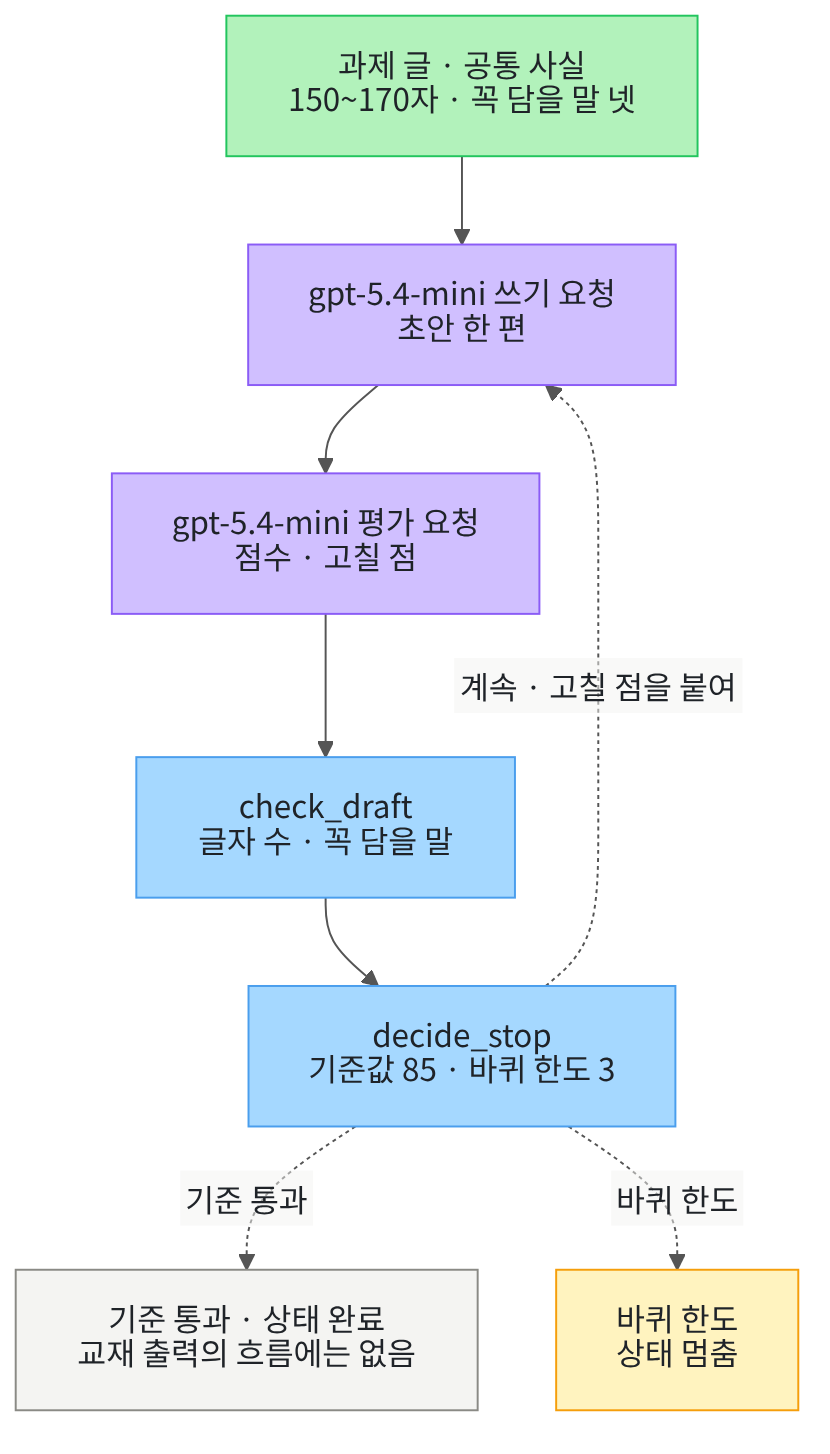

## 1. 준비

제목의 생성자(generator)는 글을 쓰는 쪽이고, 평가자(evaluator)는 쓴 글을 평가하는 쪽입니다.
이 절은 둘을 각각 「쓰는 모델」과 「평가 모델」이라고 부릅니다.
둘 다 같은 모델 `gpt-5.4-mini`이고, 지시 글만 다릅니다.
제목의 정지 조건(stopping condition)은 Ch 17 03절에서 배운 말로, 반복을 멈추는 조건입니다.

쓰고, 평가하고, 고칠 점으로 다시 쓰기를 되풀이하는 모양을 이 절은 이렇게 부릅니다.
「쓰고 평가하기 반복(evaluator-optimizer)」입니다.
첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "openai==2.29.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


openai: 2.29.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `openai: 2.29.0`과 `python-dotenv: 1.2.3`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `workflow_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
다음 셀은 클라이언트 이름과 01절에서 배운 함수 둘을 가져옵니다.

In [2]:
# 클라이언트 이름 OpenAI와 01절 함수 둘을 가져옵니다
from openai import OpenAI

from workflow_tools import ask_json, print_records

print("불러온 이름:", "OpenAI", "ask_json", "print_records")

불러온 이름: OpenAI ask_json print_records


**결과 읽기** — 출력 줄 `불러온 이름: OpenAI ask_json print_records`로 이름 셋을 가져왔습니다.
함수 `ask_json`은 요청을 한 번 보내 기록 한 줄을 남기고, 받은 JSON 글을 딕셔너리로 내놓습니다.
함수 `print_records`는 기록 목록을 줄마다 출력합니다.
두 함수 모두 01절에서 배웠습니다.

## 2. 키와 클라이언트 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`로 키를 찾았습니다.
키 값은 출력하지 않습니다.

다음 셀은 01~04절처럼 `client = OpenAI()` 한 줄로 클라이언트를 만듭니다.

In [4]:
# OpenAI 서비스에 요청을 보낼 클라이언트를 하나 만듭니다(키는 앞 셀에서 읽은 환경 변수를 씁니다)
client = OpenAI()
print("클라이언트:", type(client).__name__)

클라이언트: OpenAI


**결과 읽기** — 출력 줄 `클라이언트: OpenAI`로 클라이언트를 만들었습니다.
이 절의 쓰기 요청과 평가 요청은 모두 이 클라이언트로 보냅니다.

## 3. 과제와 공통 사실 — 쓰는 모델에게 줄 재료

이 절도 03·04절처럼 2단계 인증 안내문을 씁니다.
다음 셀은 04절과 같은 공통 사실을 적습니다.
쓰기 요청과 평가 요청이 모두 이 공통 사실을 씁니다.

In [5]:
# 모든 요청이 함께 쓸 공통 사실을 적습니다(04절과 같은 날짜·까닭·등록 방법·문의처)
notice_fact = "2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. "
notice_fact = notice_fact + "비밀번호만으로는 계정을 지키기 어렵기 때문입니다. "
notice_fact = notice_fact + "등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. "
notice_fact = notice_fact + "문의는 help@company.test로 받습니다."
print("공통 사실:")
print(notice_fact)

공통 사실:
2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.


**결과 읽기** — 라벨 줄 `공통 사실:` 아래 한 줄이 04절과 같은 공통 사실입니다.
날짜, 까닭, 등록 방법, 문의처가 한 문장씩 들어 있습니다.

다음 셀은 과제 글입니다.
안내문의 글자 수 범위와 꼭 담을 내용을 과제 글에 밝힙니다.

In [6]:
# 과제 글을 적습니다: 글자 수 범위와 꼭 담을 내용을 과제 글에 밝힙니다
task_text = "전 직원에게 보낼 2단계 인증 안내문을 150~170자로 쓰세요. 적용 날짜, 대상, 등록 방법, 문의처 주소를 담습니다."
print("과제 글:")
print(task_text)

과제 글:
전 직원에게 보낼 2단계 인증 안내문을 150~170자로 쓰세요. 적용 날짜, 대상, 등록 방법, 문의처 주소를 담습니다.


**결과 읽기** — 라벨 줄 `과제 글:` 아래 한 줄이 과제 글입니다.
글자 수는 150자 이상 170자 이하로 하라고 합니다.
적용 날짜, 대상, 등록 방법, 문의처 주소를 담으라고도 합니다.
이 두 요구는 6절에서 코드로도 검사합니다.

다음 셀은 쓰는 모델의 지시 글입니다.
앞 초안과 고칠 점을 받으면 고쳐서 새로 쓰라는 문장을 미리 넣어 둡니다.

In [7]:
# 쓰는 모델의 지시 글을 적습니다: 앞 초안과 고칠 점이 오면 고쳐서 새로 쓰게 합니다
write_instructions = "사내 안내문을 쓰는 작성자입니다. "
write_instructions = write_instructions + "과제의 요구를 지키고, 공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. "
write_instructions = write_instructions + "앞 초안과 고칠 점이 주어지면 고칠 점을 반영해 안내문을 새로 씁니다. "
# 칸 「안내문」 하나로 받아, 코드가 그 글의 글자 수를 셀 수 있게 합니다
write_instructions = write_instructions + '답은 JSON 객체 하나로만 출력합니다: {"안내문": "글"}'
print("쓰기 지시 글:")
print(write_instructions)

쓰기 지시 글:
사내 안내문을 쓰는 작성자입니다. 과제의 요구를 지키고, 공통 사실에 없는 날짜·연락처·절차는 지어내지 않습니다. 앞 초안과 고칠 점이 주어지면 고칠 점을 반영해 안내문을 새로 씁니다. 답은 JSON 객체 하나로만 출력합니다: {"안내문": "글"}


**결과 읽기** — 라벨 줄 `쓰기 지시 글:` 아래 한 줄이 쓰는 모델의 지시 글입니다.
04절 작업 모델처럼 공통 사실에 없는 날짜·연락처·절차는 지어내지 않게 했습니다.
답 모양은 칸 「안내문」 하나입니다.

다음 셀은 첫 바퀴의 쓰기 요청 글을 만듭니다.
02절에서 본 것처럼 요청 머리글에 JSON이라는 말을 넣습니다.

In [8]:
# 쓰기 머리글 뒤에 과제 글과 공통 사실을 붙여 첫 쓰기 요청 글을 만듭니다(머리글에 JSON이라는 말을 넣습니다)
write_head = "아래 과제에 맞는 안내문을 JSON으로 쓰세요.\n"
# 과제 글과 공통 사실을 이은 글은 평가 요청 글에도 그대로 씁니다
base_text = "과제: " + task_text + "\n공통 사실: " + notice_fact
first_request = write_head + base_text
print("첫 쓰기 요청 글:")
print(first_request)

첫 쓰기 요청 글:
아래 과제에 맞는 안내문을 JSON으로 쓰세요.
과제: 전 직원에게 보낼 2단계 인증 안내문을 150~170자로 쓰세요. 적용 날짜, 대상, 등록 방법, 문의처 주소를 담습니다.
공통 사실: 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.


**결과 읽기** — 라벨 줄 `첫 쓰기 요청 글:` 아래 세 줄이 첫 쓰기 요청 글입니다.
첫 줄은 쓰기 머리글, 둘째 줄은 과제 글, 셋째 줄은 공통 사실입니다.
과제 글과 공통 사실을 이은 변수 `base_text`는 평가 요청 글에도 그대로 씁니다.

## 4. 첫 바퀴 쓰기 — 쓰는 모델이 초안을 씁니다

바퀴는 Ch 17 03절에서 배운 말로, 반복을 한 번 도는 차례입니다.
이 절의 한 바퀴는 쓰기 요청 한 번과 평가 요청 한 번입니다.
먼저 첫 바퀴를 한 셀씩 따라갑니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [9]:
# 쓰는 모델에 첫 쓰기 요청을 보내 초안을 받고, 글자 수를 셉니다(모델 요청 1번)
records = []
written = ask_json(client, records, "쓰기", write_instructions, first_request)
first_draft = written["안내문"]
print("첫 초안:")
print(first_draft)
# 함수 len()은 띄어쓰기와 문장 부호까지 한 글자로 셉니다
print("글자 수:", len(first_draft))

첫 초안:
전 직원 계정에 2026년 10월 15일부터 2단계 인증을 적용합니다. 비밀번호만으로는 계정 보호가 어려워 시행합니다. 사내 포털의 보안 메뉴에서 인증 앱을 연결해 등록해 주세요. 문의는 help@company.test로 보내 주시기 바랍니다.
글자 수: 136


**결과 읽기** — 라벨 줄 `첫 초안:` 아래 한 줄이 쓰는 모델의 첫 초안입니다.
출력 줄 `글자 수:` 뒤 수는 함수 `len()`으로 센 글자 수입니다.
띄어쓰기와 문장 부호도 한 글자로 셉니다.
과제의 150~170자와 견주는 일은 6절 코드 검사가 합니다.

초안 글과 글자 수는 실행마다 달라질 수 있습니다.
교재 출력에서는 `글자 수: 136`이었고, 새 커널로 한 번 더 실행했을 때는 126자였습니다.
두 번 모두 과제의 150자보다 짧았습니다.

## 5. 평가 요청 — 평가 모델이 점수와 고칠 점을 적습니다

평가 모델은 과제와 공통 사실, 초안을 받아 점수와 고칠 점을 적습니다.
Ch 15 02절에서 평가 모델(judge)에게 점수와 까닭을 받은 것과 같은 일입니다.
다음 셀은 평가 모델의 지시 글입니다.

In [10]:
# 평가 모델의 지시 글을 적습니다: 과제의 요구를 지켰는지 0~100점과 고칠 점 한 문장으로 답하게 합니다
judge_instructions = "사내 안내문 초안을 채점하는 평가 모델입니다. "
judge_instructions = judge_instructions + "과제의 요구를 모두 지켰는지 보고 0~100 사이 정수로 점수를 매깁니다. "
judge_instructions = judge_instructions + "고칠 점은 한 문장으로 적고, 고칠 것이 없으면 없음이라고 적습니다. "
judge_instructions = judge_instructions + '답은 JSON 객체 하나로만 출력합니다: {"점수": 정수, "고칠 점": "한 문장"}'
print("평가 지시 글:")
print(judge_instructions)

평가 지시 글:
사내 안내문 초안을 채점하는 평가 모델입니다. 과제의 요구를 모두 지켰는지 보고 0~100 사이 정수로 점수를 매깁니다. 고칠 점은 한 문장으로 적고, 고칠 것이 없으면 없음이라고 적습니다. 답은 JSON 객체 하나로만 출력합니다: {"점수": 정수, "고칠 점": "한 문장"}


**결과 읽기** — 라벨 줄 `평가 지시 글:` 아래 한 줄이 평가 모델의 지시 글입니다.
과제의 요구를 모두 지켰는지 보고 0~100 사이 정수로 점수를 매기게 했습니다.
칸 「고칠 점」에는 다음 초안에서 고칠 것을 한 문장으로 적게 했습니다.

다음 셀은 평가 요청 글을 만들어 보냅니다.
평가 요청 글은 과제 글과 공통 사실 뒤에 4절 초안을 붙입니다.
이 셀에서 모델 요청이 한 번 나갑니다.

In [11]:
# 평가 요청 글을 만들어 평가 모델에 보내고, 점수와 고칠 점을 받습니다(모델 요청 1번)
judge_head = "아래 과제와 공통 사실로 초안을 평가해 JSON으로 답하세요.\n"
# 평가 모델은 과제·공통 사실·이번 초안만 받습니다(앞 바퀴 기록은 넣지 않음)
judge_request = judge_head + base_text + "\n초안: " + first_draft
judged = ask_json(client, records, "평가", judge_instructions, judge_request)
print("점수:", judged["점수"])
print("고칠 점:", judged["고칠 점"])

점수: 96
고칠 점: 문안은 요구 사항을 모두 충족하지만, 150~170자 분량에 맞는지 최종 글자 수만 다시 확인하면 좋습니다.


**결과 읽기** — 출력 줄 `점수:` 뒤 수가 평가 모델이 매긴 점수입니다.
출력 줄 `고칠 점:` 뒤 한 문장이 평가 모델이 적은 고칠 점입니다.
이 점수는 정답률이 아니라 평가 모델이 매긴 값입니다.
7절에서 이 점수를 기준값 85와 견줍니다.

점수와 고칠 점은 실행마다 달라질 수 있습니다.
교재 출력에서는 `점수: 96`이었고, 고칠 점은 요구 사항을 모두 채웠다며 글자 수만 다시 확인하라고 적었습니다.
새 커널로 한 번 더 실행했을 때는 92점이었습니다.
두 번 모두 이 절의 기준값 85보다 높았습니다.

## 6. 코드 검사 — 글자 수와 꼭 담을 말

과제 글의 두 요구, 곧 글자 수와 꼭 담을 말은 셀 수 있는 조건입니다.
셀 수 있는 조건은 모델을 부르지 않고 코드로 검사할 수 있습니다.
코드 검사는 같은 초안에 늘 같은 결과를 냅니다.
다음 셀은 글자 수를 검사하는 함수입니다. 01절 게이트처럼 문제를 글 목록으로 내놓습니다.

In [12]:
# 초안의 글자 수가 범위를 벗어났는지 검사해, 문제를 글 목록으로 내놓습니다(문제가 없으면 빈 목록)
def check_length(draft, min_length, max_length):
    problems = []
    # 함수 len()은 띄어쓰기와 문장 부호까지 한 글자로 셉니다. 어느 쪽으로 벗어났는지 적습니다
    if len(draft) < min_length:
        problems.append("글자 수가 " + str(min_length) + "자보다 적음")
    if len(draft) > max_length:
        problems.append("글자 수가 " + str(max_length) + "자보다 많음")
    return problems

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `check_length`는 초안, 최소 글자 수, 최대 글자 수를 받습니다.
글자 수는 함수 `len()`으로 세고, 범위보다 짧거나 길면 어느 쪽인지 문제 글로 적습니다.
범위 안이면 빈 목록을 내놓습니다.

다음 셀은 이 함수에 이어 꼭 담을 말까지 검사하는 함수입니다.

In [13]:
# 글자 수 검사에 이어, 꼭 담을 말이 초안에 있는지 검사합니다(문제가 없으면 빈 목록)
def check_draft(draft, min_length, max_length, must_words):
    problems = check_length(draft, min_length, max_length)
    # 꼭 담을 말이 초안에 글자 그대로 없으면 그 말마다 문제로 적습니다
    for word in must_words:
        if word not in draft:
            problems.append(word + " 없음")
    return problems

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `check_draft`는 초안, 최소 글자 수, 최대 글자 수, 꼭 담을 말 목록을 받습니다.
먼저 함수 `check_length`가 내놓은 목록을 받고, 거기에 꼭 담을 말 검사를 더합니다.
꼭 담을 말이 초안에 글자 그대로 없으면 그 말마다 문제 글을 더합니다.
문제가 없으면 빈 목록을 내놓습니다.

다음 셀은 손으로 적은 글 둘로 이 함수를 확인합니다.
모델 글이 아니라 미리 정한 값이라 `assert`로 확인할 수 있습니다.

In [14]:
# 손으로 적은 글 둘과 범위 둘로 검사 규칙을 확인합니다(정해 둔 값이라 assert로 봅니다)
hand_words = ["보안 메뉴", "help@company.test"]
short_text = "보안 메뉴에서 등록하세요."
full_text = "보안 메뉴에서 등록하고, 문의는 help@company.test로 보내세요."
short_problems = check_draft(short_text, 20, 50, hand_words)
long_problems = check_draft(full_text, 20, 40, hand_words)
fit_problems = check_draft(full_text, 20, 50, hand_words)
print("14자 글, 범위 20~50:", short_problems)
print("42자 글, 범위 20~40:", long_problems)
print("42자 글, 범위 20~50:", fit_problems)
assert [short_problems, long_problems, fit_problems] == [["글자 수가 20자보다 적음", "help@company.test 없음"], ["글자 수가 40자보다 많음"], []]

14자 글, 범위 20~50: ['글자 수가 20자보다 적음', 'help@company.test 없음']
42자 글, 범위 20~40: ['글자 수가 40자보다 많음']
42자 글, 범위 20~50: []


**결과 읽기** — 출력 줄 `14자 글, 범위 20~50: ['글자 수가 20자보다 적음', 'help@company.test 없음']`은 짧고 주소도 없는 글입니다.
출력 줄 `42자 글, 범위 20~40: ['글자 수가 40자보다 많음']`은 같은 글이 범위보다 긴 경우입니다.
출력 줄 `42자 글, 범위 20~50: []`은 문제가 없는 경우입니다.
마지막 `assert` 줄도 통과했습니다.

다음 셀은 과제 글의 조건을 코드 검사 값으로 적고, 4절 초안을 검사합니다.
이 셀은 모델을 부르지 않습니다.

In [15]:
# 과제 글의 조건을 코드 검사 값으로 적고, 4절 초안을 검사합니다(모델 요청 없음)
min_length = 150
max_length = 170
must_words = ["10월 15일", "전 직원", "보안 메뉴", "help@company.test"]
first_problems = check_draft(first_draft, min_length, max_length, must_words)
print("초안 글자 수:", len(first_draft))
print("코드 검사 문제:", first_problems)

초안 글자 수: 136
코드 검사 문제: ['글자 수가 150자보다 적음']


**결과 읽기** — 출력 줄 `코드 검사 문제: ['글자 수가 150자보다 적음']`으로 글자 수가 범위보다 짧다는 문제를 찾았습니다.
꼭 담을 말 넷은 모두 들어 있었습니다.
5절 평가 모델은 이 초안에 기준값보다 높은 점수를 매겼습니다.
코드 검사는 같은 초안에서 과제의 글자 수 요구를 어긴 것을 찾았습니다.

출력 줄 `초안 글자 수:` 뒤 수는 4절에서 센 값과 같고, 실행마다 달라질 수 있습니다.
교재 출력에서는 136자, 한 번 더 실행했을 때는 126자였고, 두 번 모두 이 문제 하나였습니다.
노트북 밖에서 첫 바퀴를 다섯 번 보냈을 때도 첫 초안은 134~148자, 평가 점수는 92~96점이었습니다.
다섯 번 모두 코드 검사는 이 문제 하나를 찾았습니다.

## 7. 정지 판정 — 다음 바퀴로 갈지 코드가 고릅니다

한 바퀴가 끝나면 코드가 멈출지, 다음 바퀴로 갈지 고릅니다.
한 바퀴의 결과는 딕셔너리 하나에 모으고, 이 절은 이것을 「바퀴 줄」이라고 부릅니다.
바퀴 줄의 칸은 초안, 글자 수, 점수, 고칠 점, 문제 다섯입니다.
바퀴 줄을 차례로 모은 목록이 `rounds`입니다.
다음 셀은 바퀴 줄 목록을 받아 정지 판정 글 하나를 내놓는 함수입니다.

In [16]:
# 바퀴 줄 목록의 마지막 줄을 보고 「기준 통과」·「바퀴 한도」·「계속」 가운데 하나를 내놓습니다
def decide_stop(rounds, threshold, turn_limit):
    last = rounds[-1]
    # 평가 점수가 기준값 이상이고, 코드 검사 문제도 없어야 통과입니다
    if last["점수"] >= threshold and len(last["문제"]) == 0:
        return "기준 통과"
    # 통과하지 못했어도 바퀴를 한도만큼 돌았으면 멈춥니다
    if len(rounds) >= turn_limit:
        return "바퀴 한도"
    return "계속"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `decide_stop`은 바퀴 줄 목록, 기준값, 바퀴 한도를 받아 마지막 바퀴 줄을 봅니다.
평가 점수가 기준값 이상이고 코드 검사 문제가 없으면 「기준 통과」를 내놓습니다.
그렇지 않아도 바퀴 줄 수가 바퀴 한도에 닿았으면 「바퀴 한도」를 내놓습니다.
둘 다 아니면 「계속」입니다.

기준값은 02절에서 신뢰도를 견준 것처럼, 모델이 적은 수를 견줄 때 쓰는 수입니다.
다음 셀은 손으로 적은 바퀴 줄로 세 갈래를 확인합니다.
함수가 읽는 칸 「점수」와 「문제」만 적었습니다.

In [17]:
# 손으로 적은 바퀴 줄로 정지 판정의 세 갈래를 확인합니다(정해 둔 값이라 assert로 봅니다)
pass_row = {"점수": 90, "문제": []}
short_row = {"점수": 95, "문제": ["글자 수가 150자보다 적음"]}
low_row = {"점수": 70, "문제": []}
hand_reasons = []
hand_reasons.append(decide_stop([pass_row], 85, 3))
hand_reasons.append(decide_stop([short_row], 85, 3))
hand_reasons.append(decide_stop([low_row], 85, 3))
hand_reasons.append(decide_stop([short_row, short_row, short_row], 85, 3))
print("판정 넷:", hand_reasons)
assert hand_reasons == ["기준 통과", "계속", "계속", "바퀴 한도"]

판정 넷: ['기준 통과', '계속', '계속', '바퀴 한도']


**결과 읽기** — 출력 줄 `판정 넷: ['기준 통과', '계속', '계속', '바퀴 한도']`의 첫째는 점수 90에 문제가 없는 줄입니다.
둘째는 점수가 95라도 코드 검사 문제가 있어 「계속」입니다.
셋째는 문제가 없어도 점수 70이 기준값 85보다 낮아 「계속」입니다.
넷째는 문제 있는 줄이 셋이라 바퀴 한도 3에 닿아 「바퀴 한도」입니다.

마지막 `assert` 줄도 통과했습니다.
다음 셀은 4~6절의 첫 바퀴 결과를 바퀴 줄로 모아 정지 판정에 넣습니다.
이 셀은 모델을 부르지 않습니다.

In [18]:
# 첫 바퀴 결과를 바퀴 줄 하나로 모으고, 기준값·바퀴 한도와 함께 정지 판정에 넣습니다(모델 요청 없음)
threshold = 85
turn_limit = 3
first_row = {"초안": first_draft, "글자 수": len(first_draft), "점수": judged["점수"]}
first_row["고칠 점"] = judged["고칠 점"]
first_row["문제"] = first_problems
rounds = [first_row]
print("평가 점수가 기준값 이상인가:", first_row["점수"] >= threshold)
print("코드 검사 문제 수:", len(first_row["문제"]))
print("정지 판정:", decide_stop(rounds, threshold, turn_limit))

평가 점수가 기준값 이상인가: True
코드 검사 문제 수: 1
정지 판정: 계속


**결과 읽기** — 출력 줄 `평가 점수가 기준값 이상인가: True`로 평가 점수만 보면 멈출 수 있었습니다.
출력 줄 `코드 검사 문제 수: 1`은 6절에서 찾은 글자 수 문제입니다.
그래서 출력 줄 `정지 판정: 계속`으로 코드는 다음 바퀴로 가기로 골랐습니다.
평가 점수만 보고 멈췄다면 과제의 글자 수를 어긴 초안이 결과가 되었을 것입니다.

새 커널로 한 번 더 실행했을 때도 이 세 줄은 같았습니다.

## 8. 고칠 점을 다음 쓰기 요청에 붙이기

다음 바퀴의 쓰는 모델은 무엇을 고쳐야 하는지 알아야 합니다.
그래서 앞 초안과 그 글자 수, 평가 모델의 고칠 점, 코드 검사의 문제를 쓰기 요청 글 끝에 붙입니다.
다음 셀은 그 덧붙일 글을 만드는 함수입니다.

In [19]:
# 마지막 바퀴 줄로 다음 쓰기 요청 글 끝에 붙일 글(앞 초안·글자 수·고칠 점·코드 검사 문제)을 만듭니다
def build_notes(rounds):
    # 첫 바퀴에는 앞 바퀴가 없으므로 아무것도 붙이지 않습니다
    if len(rounds) == 0:
        return ""
    last = rounds[-1]
    notes = "\n앞 초안: " + last["초안"] + "\n앞 초안 글자 수: " + str(last["글자 수"])
    notes = notes + "\n평가 모델의 고칠 점: " + last["고칠 점"]
    for problem in last["문제"]:
        notes = notes + "\n코드 검사의 문제: " + problem
    return notes

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_notes`는 바퀴 줄 목록의 마지막 줄을 읽습니다.
앞 초안, 앞 초안 글자 수, 평가 모델의 고칠 점을 한 줄씩 잇습니다.
코드 검사의 문제는 문제마다 한 줄씩 붙입니다.
바퀴 줄 목록이 비어 있는 첫 바퀴에는 빈 글을 내놓습니다.

다음 셀은 7절의 바퀴 줄 목록으로 둘째 바퀴 쓰기 요청 글을 만들어 봅니다.
요청은 보내지 않습니다.

In [20]:
# 7절의 바퀴 줄 목록으로 둘째 바퀴 쓰기 요청 글을 만들어 봅니다(모델 요청 없음)
second_request = first_request + build_notes(rounds)
print("둘째 쓰기 요청 글:")
print(second_request)
print("바퀴 줄이 없을 때 붙는 글이 빈 글인가:", build_notes([]) == "")

둘째 쓰기 요청 글:
아래 과제에 맞는 안내문을 JSON으로 쓰세요.
과제: 전 직원에게 보낼 2단계 인증 안내문을 150~170자로 쓰세요. 적용 날짜, 대상, 등록 방법, 문의처 주소를 담습니다.
공통 사실: 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어렵기 때문입니다. 등록은 사내 포털의 보안 메뉴에서 인증 앱을 연결하면 됩니다. 문의는 help@company.test로 받습니다.
앞 초안: 전 직원 계정에 2026년 10월 15일부터 2단계 인증을 적용합니다. 비밀번호만으로는 계정 보호가 어려워 시행합니다. 사내 포털의 보안 메뉴에서 인증 앱을 연결해 등록해 주세요. 문의는 help@company.test로 보내 주시기 바랍니다.
앞 초안 글자 수: 136
평가 모델의 고칠 점: 문안은 요구 사항을 모두 충족하지만, 150~170자 분량에 맞는지 최종 글자 수만 다시 확인하면 좋습니다.
코드 검사의 문제: 글자 수가 150자보다 적음
바퀴 줄이 없을 때 붙는 글이 빈 글인가: True


**결과 읽기** — 라벨 줄 `둘째 쓰기 요청 글:` 아래가 둘째 바퀴의 쓰기 요청 글입니다.
첫 세 줄은 3절의 첫 쓰기 요청 글과 같습니다.
그 아래에 앞 초안, 앞 초안 글자 수, 평가 모델의 고칠 점이 한 줄씩 붙었습니다.
마지막 줄 `코드 검사의 문제: 글자 수가 150자보다 적음`이 6절에서 찾은 문제입니다.
출력 줄 `바퀴 줄이 없을 때 붙는 글이 빈 글인가: True`로 첫 바퀴에는 아무것도 붙지 않습니다.

앞 초안과 그 글자 수, 고칠 점은 4~5절의 답이라 실행마다 달라질 수 있습니다.
교재 출력에서는 `앞 초안 글자 수: 136`이었습니다.

## 9. 흐름 함수로 묶기

4~8절에서 한 일을 함수로 묶어, 바퀴 한도까지 되풀이할 수 있게 합니다.
먼저 한 바퀴, 곧 쓰기 요청과 평가 요청과 코드 검사를 함수 하나로 묶습니다.
쓰기 요청 글은 8절처럼 첫 쓰기 요청 글 끝에 함수 `build_notes`의 글을 붙여 만듭니다.

In [21]:
# 한 바퀴: 쓰기 요청과 평가 요청을 한 번씩 보내고 초안을 코드로 검사해, 바퀴 줄 하나를 내놓습니다(모델 요청 2번)
def write_and_judge(client, records, setup, base_text, rounds):
    write_request = setup["쓰기 머리글"] + base_text + build_notes(rounds)
    written = ask_json(client, records, "쓰기", setup["쓰기 지시 글"], write_request)
    draft = written["안내문"]
    judge_request = setup["평가 머리글"] + base_text + "\n초안: " + draft
    judged = ask_json(client, records, "평가", setup["평가 지시 글"], judge_request)
    row = {"초안": draft, "글자 수": len(draft), "점수": judged["점수"], "고칠 점": judged["고칠 점"]}
    row["문제"] = check_draft(draft, setup["최소 글자 수"], setup["최대 글자 수"], setup["필수 말"])
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `write_and_judge`는 쓰기 요청과 평가 요청을 한 번씩 보내고, 초안을 코드로 검사합니다.
결과는 7절과 같은 칸 다섯의 바퀴 줄 하나로 내놓습니다.
지시 글과 머리글, 검사 값은 설정 딕셔너리 `setup`에서 꺼냅니다.
이 함수를 한 번 부르면 모델 요청이 두 번 나갑니다.

다음 셀은 멈춘 까닭으로 흐름 결과를 만드는 함수입니다.

In [22]:
# 멈춘 까닭으로 흐름 결과를 만듭니다: 기준을 통과했을 때만 상태 「완료」, 바퀴 한도면 「멈춤」
def finish_loop(rounds, reason):
    status = "멈춤"
    if reason == "기준 통과":
        status = "완료"
    return {"상태": status, "멈춘 까닭": reason, "바퀴": rounds, "안내문": rounds[-1]["초안"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `finish_loop`는 멈춘 까닭이 「기준 통과」일 때만 칸 「상태」를 「완료」로 둡니다.
「바퀴 한도」로 멈췄으면 「멈춤」입니다.
마지막 초안은 두 경우 모두 칸 「안내문」에 담지만, 바퀴 한도로 멈춘 초안은 기준을 통과한 글이 아닙니다.
01~04절처럼 흐름 결과에 칸 「상태」를 두어 둘을 가릅니다.

다음 셀은 쓰고 평가하기 반복의 흐름 함수입니다.
함수 `decide_stop`이 「계속」이 아닌 판정을 내놓을 때까지 바퀴를 돕니다.

In [23]:
# 쓰고 평가하기 반복 흐름: 바퀴마다 쓰기·평가·코드 검사를 하고, 멈출지는 코드가 고릅니다(모델 요청 = 바퀴 수 × 2)
def run_write_judge_loop(client, records, setup, task_text, fact):
    base_text = "과제: " + task_text + "\n공통 사실: " + fact
    rounds = []
    for turn in range(setup["바퀴 한도"]):
        rounds.append(write_and_judge(client, records, setup, base_text, rounds))
        reason = decide_stop(rounds, setup["기준값"], setup["바퀴 한도"])
        # 판정이 「계속」이 아니면 남은 바퀴를 돌지 않고 끝냅니다
        if reason != "계속":
            break
    return finish_loop(rounds, reason)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_write_judge_loop`는 바퀴 한도만큼 도는 `for` 안에서 한 바퀴씩 실행합니다.
바퀴마다 바퀴 줄을 목록에 더하고, 함수 `decide_stop`으로 정지 판정을 받습니다.
판정이 「계속」이 아니면 Ch 17 05절에서 본 `break`로 반복을 바로 끝냅니다.
변수 `turn`은 도는 횟수를 정할 뿐 함수 안에서 쓰지 않습니다.

다음 바퀴로 갈지 멈출지는 이 함수와 함수 `decide_stop`의 코드가 고릅니다.
두 모델은 초안과 점수, 고칠 점만 씁니다.
Ch 17 01절처럼 단계마다 고른 쪽을 적어 보면 모두 코드라 워크플로우입니다.
이 챕터의 기록 줄에는 그 칸을 두지 않았습니다.
다음 셀은 이 흐름에 쓸 설정 한 벌을 모읍니다.

In [24]:
# 쓰고 평가하기 흐름에 쓸 설정 한 벌을 딕셔너리 하나에 모읍니다(3~7절에서 적은 값 그대로)
loop_setup = {
    "쓰기 지시 글": write_instructions, "쓰기 머리글": write_head,
    "평가 지시 글": judge_instructions, "평가 머리글": judge_head,
    "최소 글자 수": min_length, "최대 글자 수": max_length, "필수 말": must_words,
    "기준값": threshold, "바퀴 한도": turn_limit,
}
setup_keys = list(loop_setup.keys())
print("설정 칸 수:", len(setup_keys))
print("설정 칸:", setup_keys)

설정 칸 수: 9
설정 칸: ['쓰기 지시 글', '쓰기 머리글', '평가 지시 글', '평가 머리글', '최소 글자 수', '최대 글자 수', '필수 말', '기준값', '바퀴 한도']


**결과 읽기** — 출력 줄 `설정 칸 수: 9`로 아홉 칸을 모았습니다.
라벨 `설정 칸:` 뒤 목록은 두 모델의 지시 글과 머리글, 코드 검사 값 셋, 기준값, 바퀴 한도입니다.
값은 3~7절에서 적은 것을 그대로 넣었습니다.

## 10. 흐름 실행 — 바퀴 한도 3

흐름 함수를 바퀴 한도 3으로 실행합니다.
첫 바퀴는 4~5절과 같은 요청을 다시 보냅니다.
요청은 바퀴마다 두 번이라 많아야 여섯 번입니다.
기록 목록은 새로 만들어 이 흐름의 요청만 담습니다.

In [25]:
# 흐름 함수를 바퀴 한도 3으로 실행합니다(모델 요청 = 바퀴 수 × 2, 많아야 6번)
loop_records = []
loop_result = run_write_judge_loop(client, loop_records, loop_setup, task_text, notice_fact)
print("상태:", loop_result["상태"])
print("멈춘 까닭:", loop_result["멈춘 까닭"])
print("바퀴 수:", len(loop_result["바퀴"]))
print("요청 수(기록 줄 수):", len(loop_records))

상태: 멈춤
멈춘 까닭: 바퀴 한도
바퀴 수: 3
요청 수(기록 줄 수): 6


**결과 읽기** — 출력 줄 넷이 흐름 결과입니다.
칸 「상태」와 「멈춘 까닭」은 함수 `decide_stop`의 판정으로 정해졌습니다.
요청 수는 바퀴 수의 두 배이고, 바퀴 한도가 3이라 여섯 번을 넘지 않습니다.

이번 실행에서는 `상태: 멈춤`, `멈춘 까닭: 바퀴 한도`, `바퀴 수: 3`, `요청 수(기록 줄 수): 6`이었습니다.
세 바퀴 모두 통과하지 못해 바퀴 한도에서 멈춘 것입니다.
새 커널로 한 번 더 실행했을 때는 둘째 바퀴 초안이 통과해 「기준 통과」로 멈췄고, 요청은 네 번이었습니다.
노트북 밖 다섯 번은 모두 셋째 바퀴까지 갔고, 기준 통과 둘과 바퀴 한도 셋이었습니다.
멈춘 까닭과 바퀴 수는 실행한 때에 따라 달라질 수 있습니다.

다음 셀은 바퀴 줄을 한 줄씩 출력하고, 마지막 초안을 봅니다.
이 셀은 모델을 부르지 않습니다.

In [26]:
# 바퀴마다 글자 수·평가 점수·코드 검사 문제와 고칠 점을 출력하고, 마지막 초안을 봅니다(모델 요청 없음)
print("바퀴 | 글자 수 | 점수 | 코드 검사 문제")
for i in range(len(loop_result["바퀴"])):
    row = loop_result["바퀴"][i]
    print(i + 1, "|", row["글자 수"], "|", row["점수"], "|", row["문제"])
    print("   고칠 점:", row["고칠 점"])
print("마지막 초안:")
print(loop_result["안내문"])

바퀴 | 글자 수 | 점수 | 코드 검사 문제
1 | 131 | 95 | ['글자 수가 150자보다 적음']
   고칠 점: 대상과 등록 방법, 문의처는 잘 담았지만 글자 수가 150~170자인지 다시 맞춰 더 정확히 조정하세요.
2 | 132 | 96 | ['글자 수가 150자보다 적음']
   고칠 점: 문안이 150~170자 범위에 맞는지 확인하고, 대상이 전 직원임을 더 자연스럽게 드러내면 좋습니다.
3 | 138 | 96 | ['글자 수가 150자보다 적음']
   고칠 점: 문안이 과제 조건을 대부분 충족하지만 글자 수가 150~170자 범위인지 다시 맞춰 보세요.
마지막 초안:
[안내] 2026년 10월 15일부터 전 직원 계정에 2단계 인증을 적용합니다. 비밀번호만으로는 계정을 지키기 어려워 보안을 강화합니다. 전 직원은 사내 포털의 보안 메뉴에서 인증 앱을 연결해 등록해 주세요. 문의: help@company.test


**결과 읽기** — 라벨 줄 `바퀴 | 글자 수 | 점수 | 코드 검사 문제` 아래 줄마다 바퀴 하나입니다.
줄마다 그 바퀴 초안의 글자 수, 평가 점수, 코드 검사 문제가 있고, 다음 줄이 고칠 점입니다.
라벨 줄 `마지막 초안:` 아래가 흐름 결과의 칸 「안내문」입니다.

바퀴 줄의 값은 실행마다 달라질 수 있습니다.
교재 출력에서는 세 바퀴 글자 수가 131, 132, 138자로 모두 150자보다 짧았습니다.
점수는 95, 96, 96점이었고, 고칠 점도 세 바퀴 모두 글자 수를 확인하거나 다시 맞추라고 적었습니다.
쓰는 모델은 코드 검사의 문제를 받고도 세 바퀴 동안 150자에 닿지 못했습니다.

한 번 더 실행했을 때는 첫 바퀴가 132자에 100점, 고칠 점 「없음」이었습니다.
둘째 바퀴 155자 초안이 코드 검사를 지나 「기준 통과」로 멈췄습니다.
두 번 모두 첫 바퀴는 평가 점수가 기준값을 넘었지만 코드 검사에 걸렸습니다.
4절과 같은 요청이었지만 이 흐름의 첫 초안은 4절 초안과 글자가 달랐습니다.

다음 셀은 이 흐름의 기록 줄을 출력합니다.
요청 수를 바퀴 수로 셈한 값도 함께 봅니다.

In [27]:
# 흐름의 기록 줄을 출력하고, 요청 수를 바퀴 수로 셈한 값과 견줍니다(모델 요청 없음)
requests_per_turn = 2
print("바퀴 수 × 2:", len(loop_result["바퀴"]) * requests_per_turn)
print_records(loop_records)

바퀴 수 × 2: 6
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 쓰기 | 221 | 81
2 | 평가 | 297 | 58
3 | 쓰기 | 360 | 82
4 | 평가 | 298 | 59
5 | 쓰기 | 363 | 85
6 | 평가 | 301 | 54


**결과 읽기** — 라벨 줄 `번호 | 단계 | 입력 토큰 | 출력 토큰` 아래 기록 줄은 「쓰기」와 「평가」가 번갈아 쌓였습니다.
한 바퀴가 기록 두 줄이라, 출력 줄 `바퀴 수 × 2:` 뒤 수와 기록 줄 수가 같습니다.
첫 줄 `1 | 쓰기 | 221`의 입력 토큰은 한 번 더 실행했을 때도 같았습니다.
둘째 바퀴부터 쓰기 요청의 입력 토큰이 커진 것은 앞 초안과 고칠 점을 붙였기 때문입니다.

교재 출력에서는 기록 줄이 여섯 줄이고 `바퀴 수 × 2: 6`이었습니다.
기록 줄 수와 토큰 수는 실행마다 달라질 수 있습니다.

## 11. 값 바꿔 보기 · 바퀴 한도 1

바꿀 값은 설정의 칸 「바퀴 한도」 하나입니다. 3을 1로 바꿉니다.
과제 글과 공통 사실, 다른 설정은 그대로 둡니다.
딕셔너리 메서드 `copy()`로 설정을 복사해 바꾸므로 10절 설정은 그대로 남습니다.

실행 전에 예상해 봅니다.
첫 바퀴 초안이 코드 검사를 지나지 못하면, 한 바퀴 만에 「바퀴 한도」로 멈출 것입니다.
그러면 칸 「상태」는 「멈춤」이고, 요청은 두 번일 것입니다.
이 셀에서 모델 요청이 많아야 두 번 나갑니다.

In [28]:
# 설정을 복사해 바퀴 한도만 1로 바꾸고 흐름 함수를 실행합니다(모델 요청 = 바퀴 수 × 2, 많아야 2번)
one_turn_setup = loop_setup.copy()
one_turn_setup["바퀴 한도"] = 1
one_records = []
one_result = run_write_judge_loop(client, one_records, one_turn_setup, task_text, notice_fact)
print("상태:", one_result["상태"])
print("멈춘 까닭:", one_result["멈춘 까닭"])
print("바퀴 한도(10절 → 11절):", loop_setup["바퀴 한도"], one_turn_setup["바퀴 한도"])
print("요청 수(10절 → 11절):", len(loop_records), len(one_records))

상태: 멈춤
멈춘 까닭: 바퀴 한도
바퀴 한도(10절 → 11절): 3 1
요청 수(10절 → 11절): 6 2


**결과 읽기** — 출력 줄 `상태: 멈춤`과 `멈춘 까닭: 바퀴 한도`로 흐름은 한 바퀴 만에 멈췄습니다.
출력 줄 `바퀴 한도(10절 → 11절): 3 1`이 바꾼 값입니다.
첫 바퀴 초안이 코드 검사를 지나지 못해, 예상대로 둘째 바퀴 없이 멈췄습니다.
11절 흐름의 요청은 쓰기 한 번과 평가 한 번, 두 번입니다.

출력 줄 `요청 수(10절 → 11절): 6 2`의 앞 수는 10절 흐름의 바퀴 수에 따라 달라집니다.
새 커널로 한 번 더 실행했을 때는 4와 2였습니다.
두 번 모두 11절 흐름은 「바퀴 한도」로 멈췄고 요청은 두 번이었습니다.

다음 셀은 바퀴 한도 1로 멈춘 흐름의 바퀴 줄과 마지막 초안을 봅니다.
이 셀은 모델을 부르지 않습니다.

In [29]:
# 바퀴 한도 1로 멈춘 흐름의 바퀴 줄과 마지막 초안을 봅니다(모델 요청 없음)
last_row = one_result["바퀴"][-1]
print("글자 수:", last_row["글자 수"])
print("평가 점수:", last_row["점수"])
print("코드 검사 문제:", last_row["문제"])
print("마지막 초안:")
print(one_result["안내문"])

글자 수: 126
평가 점수: 92
코드 검사 문제: ['글자 수가 150자보다 적음']
마지막 초안:
전 직원 계정에 2단계 인증을 2026년 10월 15일부터 적용합니다. 비밀번호만으로는 계정 보호가 어려워 보안을 강화합니다. 사내 포털의 보안 메뉴에서 인증 앱을 연결해 등록해 주세요. 문의: help@company.test


**결과 읽기** — 출력 줄 `코드 검사 문제: ['글자 수가 150자보다 적음']`으로 마지막 초안은 과제의 글자 수를 지키지 못했습니다.
그래서 칸 「상태」가 「완료」가 아니라 「멈춤」입니다.
라벨 줄 `마지막 초안:` 아래 글은 흐름 결과의 칸 「안내문」에 남지만, 기준을 통과한 글이 아닙니다.

글자 수와 평가 점수는 실행마다 달라질 수 있습니다.
교재 출력에서는 `글자 수: 126`, `평가 점수: 92`였고, 한 번 더 실행했을 때는 143자에 96점이었습니다.
두 번 모두 평가 점수는 기준값 85보다 높았습니다.

## 정리

1. 쓰는 모델과 평가 모델에게 요청을 번갈아 보내고, 고칠 점과 코드 검사의 문제를 다음 쓰기 요청에 붙였습니다.
2. 첫 바퀴 초안은 평가 점수가 기준값을 넘었지만, 코드 검사가 글자 수 문제를 찾아 다음 바퀴로 갔습니다.
3. 멈춤은 코드가 기준값과 바퀴 한도로 골랐고, 바퀴 한도가 3이면 요청은 많아야 여섯 번입니다.

06절에서는 다섯 흐름 함수를 같은 과제에 적용하고, 요청 수와 토큰 수를 한 표에서 견줍니다.